In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:
from google.colab import files

uploaded = files.upload()


Saving IMDb_Movies_India[1].csv to IMDb_Movies_India[1].csv


In [12]:
import pandas as pd

df = pd.read_csv("IMDb_Movies_India[1].csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)



Dataset loaded successfully!
Dataset shape: (15509, 10)


In [13]:
df.head()


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [14]:
print(df.columns.tolist())


['Name', 'Year', 'Duration', 'Genre', 'Rating', 'Votes', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']


In [15]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB


In [16]:
df.tail()


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
15504,Zulm Ko Jala Doonga,(1988),NaN,Action,4.6,11,Mahendra Shah,Naseeruddin Shah,Sumeet Saigal,Suparna Anand
15505,Zulmi,(1999),129 min,"Action, Drama",4.5,655,Kuku Kohli,Akshay Kumar,Twinkle Khanna,Aruna Irani
15506,Zulmi Raj,(2005),NaN,Action,NaN,NaN,Kiran Thej,Sangeeta Tiwari,NaN,NaN
15507,Zulmi Shikari,(1988),NaN,Action,NaN,NaN,NaN,NaN,NaN,NaN
15508,Zulm-O-Sitam,(1998),130 min,"Action, Drama",6.2,20,K.C. Bokadia,Dharmendra,Jaya Prada,Arjun Sarja


In [17]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,15509,13838,Mamta,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,14981,102,(2019),410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration,7240,182,120 min,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genre,13632,485,Drama,2780,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,7919.0,NaN,NaN,NaN,5.841621,1.381777,1.1,4.9,6.0,6.8,10.0
Votes,7920,2034,8,227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Director,14984,5938,Jayant Desai,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Actor 1,13892,4718,Ashok Kumar,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Actor 2,13125,4891,Rekha,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Actor 3,12365,4820,Pran,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
df.isnull().sum()


,0
Name,0
Year,528
Duration,8269
Genre,1877
Rating,7590
Votes,7589
Director,525
Actor 1,1617
Actor 2,2384
Actor 3,3144


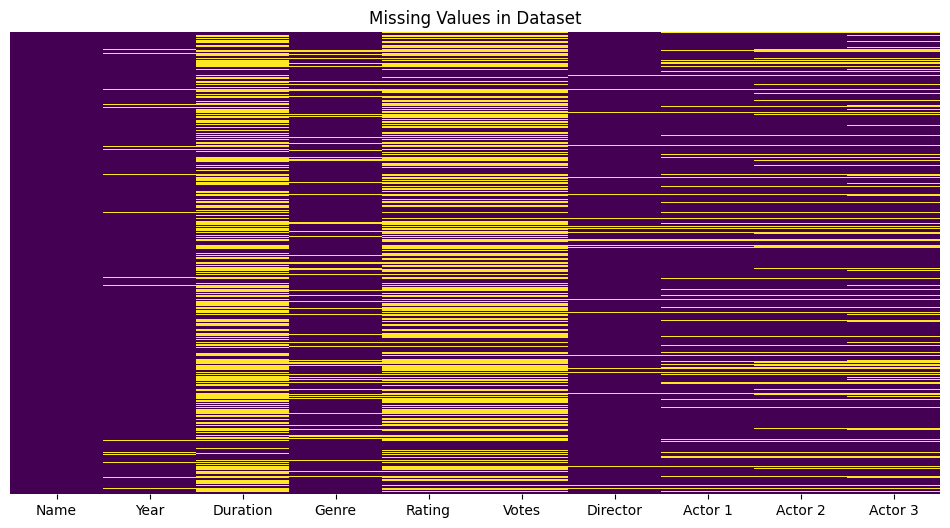

In [19]:
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(),
            cbar=False,
            yticklabels=False,
            cmap="viridis")

plt.title("Missing Values in Dataset")
plt.show()


In [20]:
df["Rating"].head()


,Rating
0,NaN
1,7.0
2,NaN
3,4.4
4,NaN


In [21]:
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")


In [22]:
df = df.dropna(subset=["Rating"])


In [23]:
print("Dataset shape after removing missing ratings:", df.shape)


Dataset shape after removing missing ratings: (7919, 10)


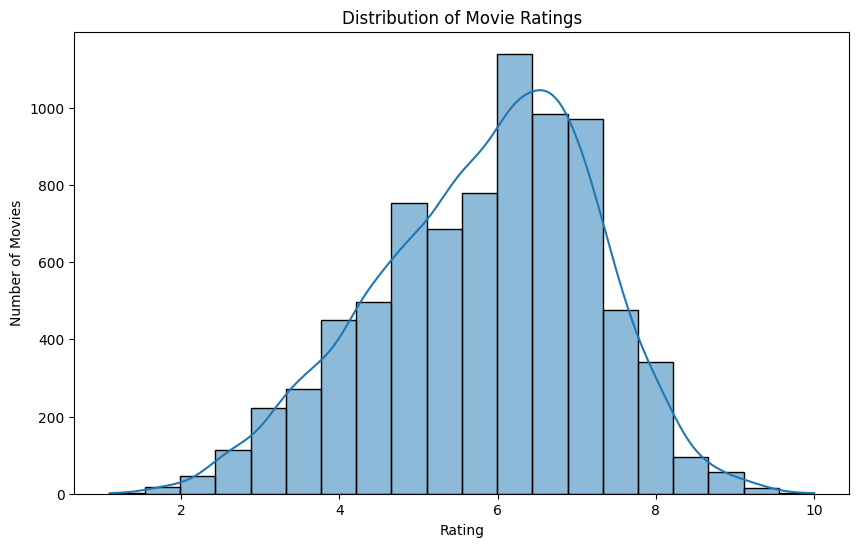

In [24]:
plt.figure(figsize=(10,6))

sns.histplot(df["Rating"], bins=20, kde=True)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Movies")

plt.show()


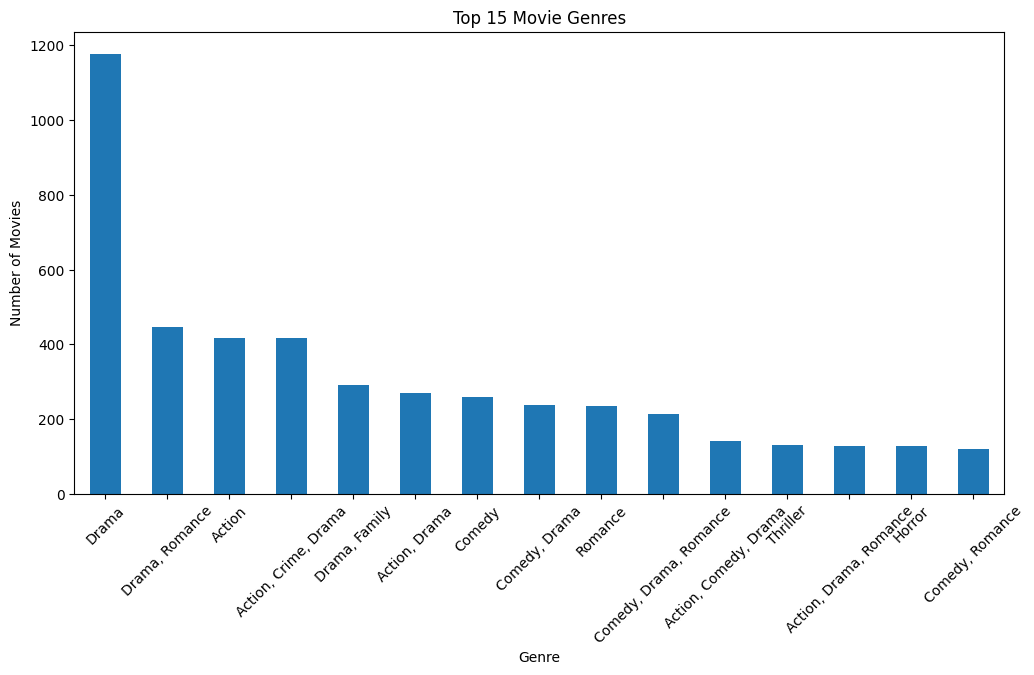

In [25]:
genre_counts = df["Genre"].value_counts().head(15)

plt.figure(figsize=(12,6))

genre_counts.plot(kind="bar")

plt.title("Top 15 Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")

plt.xticks(rotation=45)
plt.show()


In [26]:
df["Main_Genre"] = df["Genre"].fillna("Unknown").str.split(",").str[0].str.strip()


In [27]:
genre_rating = df.groupby("Main_Genre")["Rating"].mean().sort_values(ascending=False)

print(genre_rating)


Main_Genre
Documentary    7.613287
Biography      6.666667
History        6.606667
Music          6.460000
Sci-Fi         6.433333
Fantasy        6.246154
Drama          6.172393
Family         6.107059
Adventure      6.048125
Crime          6.016327
Unknown        5.999020
Musical        5.984298
Animation      5.956164
Comedy         5.811429
Mystery        5.807792
Sport          5.800000
Romance        5.555556
Action         5.426019
Thriller       5.330435
Horror         4.687234
War            4.333333
Name: Rating, dtype: float64


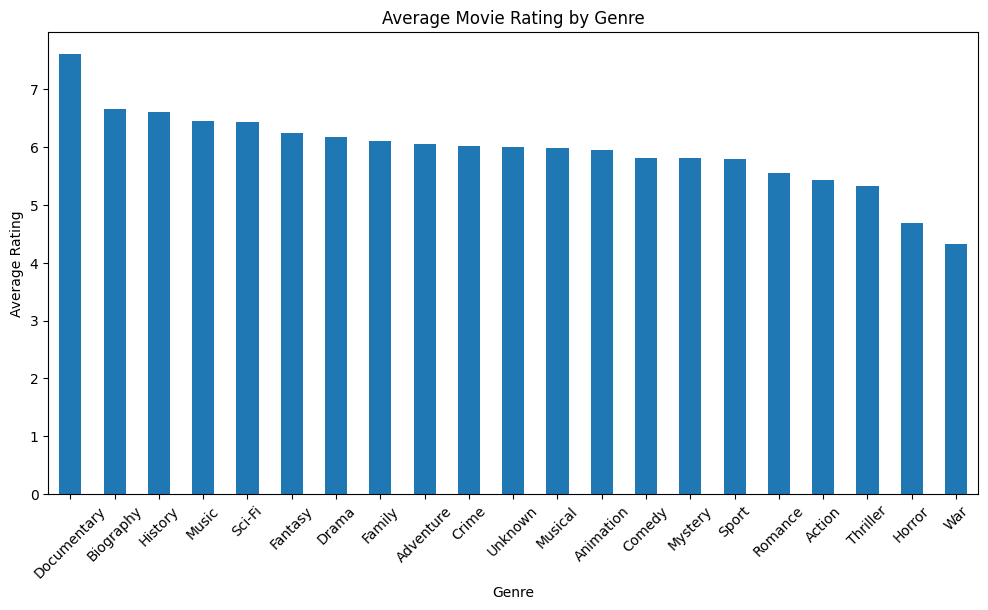

In [28]:
plt.figure(figsize=(12,6))

genre_rating.plot(kind="bar")

plt.title("Average Movie Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")

plt.xticks(rotation=45)
plt.show()


In [29]:
df["Year"].head(10)


,Year
1,(2019)
3,(2019)
5,(1997)
6,(2005)
8,(2012)
9,(2014)
10,(2004)
11,(2016)
12,(1991)
13,(2012)


In [30]:
df["Year"] = df["Year"].astype(str).str.extract(r"(\d{4})")
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")


In [31]:
df[["Year", "Rating"]].head()


,Year,Rating
1,2019,7.0
3,2019,4.4
5,1997,4.7
6,2005,7.4
8,2012,5.6


In [32]:
df["Duration"] = df["Duration"].astype(str).str.extract(r"(\d+)")[0]
df["Duration"] = pd.to_numeric(df["Duration"], errors="coerce")


In [33]:
df["Duration"].head()


,Duration
1,109.0
3,110.0
5,147.0
6,142.0
8,82.0


In [34]:
df["Votes"] = df["Votes"].astype(str).str.replace(",", "", regex=False)

df["Votes"] = pd.to_numeric(df["Votes"], errors="coerce")


In [35]:
df["Votes"].head()


,Votes
1,8
3,35
5,827
6,1086
8,326


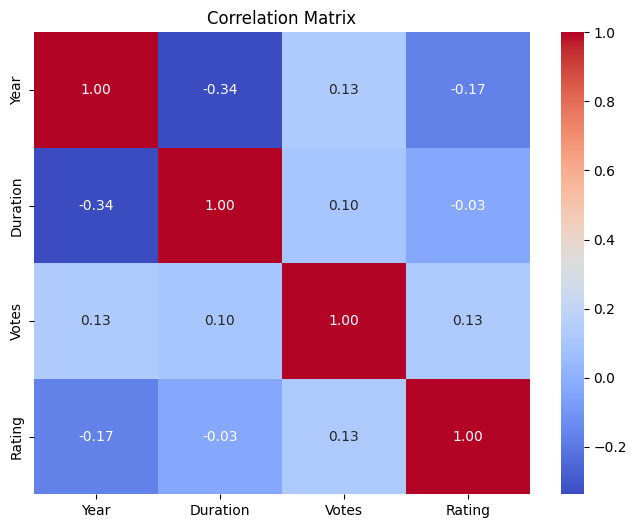

In [36]:
numeric_columns = ["Year", "Duration", "Votes", "Rating"]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()


In [37]:
features = [
    "Genre",
    "Director",
    "Actor 1",
    "Actor 2",
    "Actor 3",
    "Year",
    "Duration",
    "Votes"
]

for column in features:
    print(column, "->", column in df.columns)


Genre -> True
Director -> True
Actor 1 -> True
Actor 2 -> True
Actor 3 -> True
Year -> True
Duration -> True
Votes -> True


In [38]:
X = df[features]
y = df["Rating"]


In [39]:
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (7919, 8)
y shape: (7919,)


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (6335, 8)
Testing data: (1584, 8)


In [41]:
numeric_features = [
    "Year",
    "Duration",
    "Votes"
]


In [42]:
categorical_features = [
    "Genre",
    "Director",
    "Actor 1",
    "Actor 2",
    "Actor 3"
]


In [43]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)


In [44]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=2
        ))
    ]
)


In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


In [46]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    max_depth=20
)


In [47]:
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)


In [48]:
pipeline.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [49]:
y_pred = pipeline.predict(X_test)


In [50]:
results = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": y_pred
})

results.head(10)


,Actual Rating,Predicted Rating
0,3.3,4.297479
1,5.3,5.115861
2,5.7,5.504984
3,7.2,6.303529
4,3.5,5.492521
5,7.2,6.075827
6,3.8,5.248754
7,6.9,6.976008
8,5.2,5.770994
9,7.4,6.224968


In [51]:
mae = mean_absolute_error(y_test, y_pred)


In [52]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))


In [53]:
r2 = r2_score(y_test, y_pred)


In [54]:
print("Model Performance")
print("--------------------------")
print("Mean Absolute Error:", round(mae, 3))
print("Root Mean Squared Error:", round(rmse, 3))
print("R² Score:", round(r2, 3))


Model Performance
--------------------------
Mean Absolute Error: 0.814
Root Mean Squared Error: 1.084
R² Score: 0.368


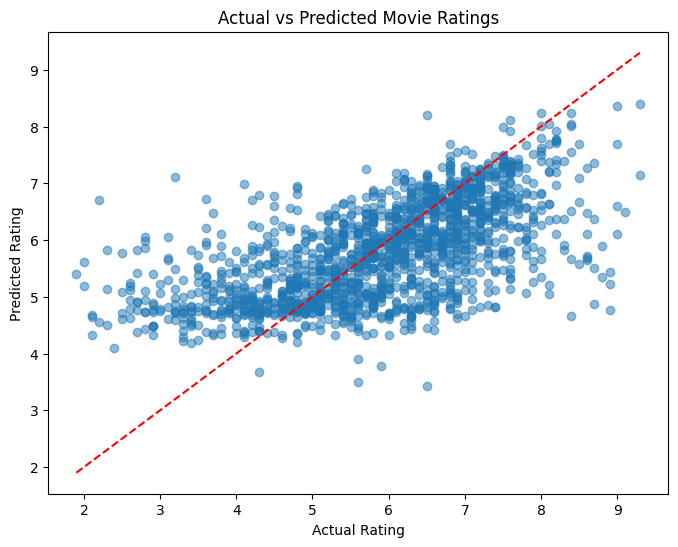

In [55]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Movie Ratings")

plt.show()


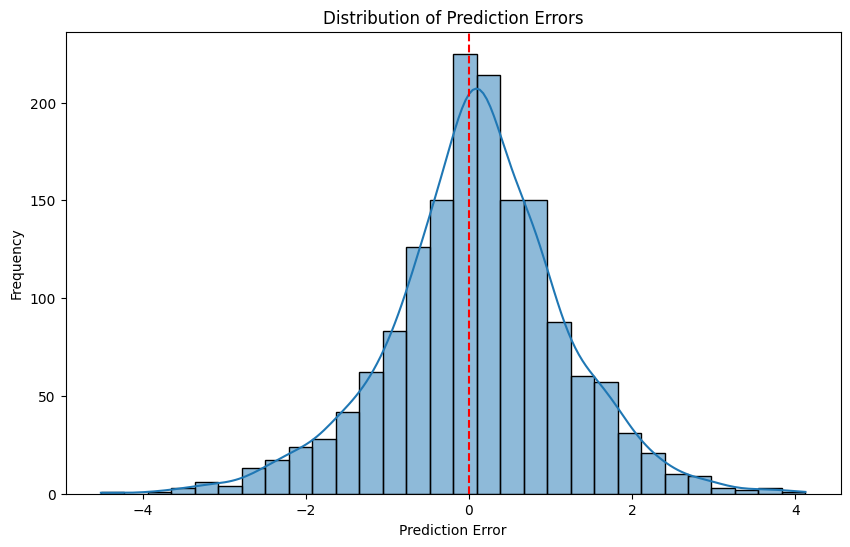

In [56]:
errors = y_test - y_pred

plt.figure(figsize=(10,6))

sns.histplot(errors, bins=30, kde=True)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()


In [57]:
from sklearn.linear_model import Ridge


In [58]:
ridge_model = Ridge(alpha=10)


In [59]:
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", ridge_model)
    ]
)


In [60]:
ridge_pipeline.fit(X_train, y_train)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Year', 'Duration',
                                                   'Votes']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 min_frequency=2))]),
                                                  ['Genre', 'Director',
                                                   'Actor 1', 'Actor 2',
                                                   'Actor 3'])])),
                ('model', Ridge(alpha=10))])

In [61]:
ridge_pred = ridge_pipeline.predict(X_test)


In [62]:
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")
print("------------------------")
print("MAE :", round(ridge_mae, 3))
print("RMSE:", round(ridge_rmse, 3))
print("R²  :", round(ridge_r2, 3))


Ridge Regression
------------------------
MAE : 1.047
RMSE: 1.312
R²  : 0.074


In [63]:
comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        ridge_mae,
        mae
    ],
    "RMSE": [
        ridge_rmse,
        rmse
    ],
    "R2 Score": [
        ridge_r2,
        r2
    ]
})

comparison


,Model,MAE,RMSE,R2 Score
0,Ridge Regression,1.047385,1.311842,0.074344
1,Random Forest Regression,0.814495,1.084339,0.367563


In [64]:
new_movie = pd.DataFrame({
    "Genre": ["Action, Drama"],
    "Director": ["Example Director"],
    "Actor 1": ["Example Actor 1"],
    "Actor 2": ["Example Actor 2"],
    "Actor 3": ["Example Actor 3"],
    "Year": [2025],
    "Duration": [140],
    "Votes": [10000]
})


In [65]:
predicted_rating = pipeline.predict(new_movie)

print(
    "Predicted Movie Rating:",
    round(predicted_rating[0], 2)
)


Predicted Movie Rating: 6.49


In [66]:
handle_unknown="ignore"


In [67]:
import joblib

joblib.dump(
    pipeline,
    "movie_rating_prediction_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [68]:
from google.colab import files

files.download("movie_rating_prediction_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
df.to_csv(
    "cleaned_movie_dataset.csv",
    index=False
)


In [70]:
files.download("cleaned_movie_dataset.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>